In [12]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080229
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] pytorch_env
[学号] 20244080229
[机器指纹] 1dcfe6052a702801
[RUN_ID] 20244080229-1dcfe6052a702801


实验1：NumPy 数组、数据类型与索引

In [12]:
import numpy as np
arr_int=np.array([1,2,3])
arr_float=np.array([1.0,2.5,3.6])
arr_bool=np.array([True,False,True])

for name,arr in [("整数",arr_int),("浮点数",arr_float),("布尔值",arr_bool)]:
     print(f"{name}数组；{arr}")
     print(f"dtype:{arr.dtype}")
     print(f"shape:{arr.shape}")
     print(f"ndim:{arr.ndim}")

整数数组；[1 2 3]
dtype:int64
shape:(3,)
ndim:1
浮点数数组；[1.  2.5 3.6]
dtype:float64
shape:(3,)
ndim:1
布尔值数组；[ True False  True]
dtype:bool
shape:(3,)
ndim:1


In [29]:
import numpy as np
a=np.arange(12)
print("原始一维数组：")
print(a)
print(f"形状：{a.shape},元素总数：{a.size}\n")

b=a.reshape(3,4)
print("重塑为(3,4)：")
print(b)
print(f"形状：{b.shape},元素总数：{b.size}\n")

c=a.reshape(2,3,2)
print("重塑为(2,3,2)：")
print(c)
print(f"形状：{c.shape},元素总数：{c.size}\n")
#重塑前后的元素总数必须严格相等
row2=b[1,:]
print("取第二行：")
print(row2)
print(f"形状:{row2.shape}\n")
col1_3=b[:,1:3]
print("取第一至第三列：")
print(col1_3)
print(f"形状:\n{col1_3.shape}\n")
gt6=b[b>6]
print("取大于6的元素：")
print(gt6)
print(f"形状:{gt6.shape}\n")

原始一维数组：
[ 0  1  2  3  4  5  6  7  8  9 10 11]
形状：(12,),元素总数：12

重塑为(3,4)：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状：(3, 4),元素总数：12

重塑为(2,3,2)：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
形状：(2, 3, 2),元素总数：12

取第二行：
[4 5 6 7]
形状:(4,)

取第一至第三列：
[[ 1  2]
 [ 5  6]
 [ 9 10]]
形状:
(3, 2)

取大于6的元素：
[ 7  8  9 10 11]
形状:(5,)



In [37]:
import numpy as np
a=np.arange(10)
print("原始一维数组：")
print(a)
num1=(a<2)|(a>7)
result1=a[num1]
print("小于2或大于7的元素为：")
print(result1)
num2=(a>3)&(a<7)
result2=a[num2]
print("大于3且小于7的元素为：")
print(result2)

原始一维数组：
[0 1 2 3 4 5 6 7 8 9]
小于2或大于7的元素为：
[0 1 8 9]
大于3且小于7的元素为：
[4 5 6]


In [46]:
import numpy as np
a=np.array([[1,2],[3,4]])
b=np.array([[5,6],[7,8]])
print("原始数组分别为：")
print(f"a:{a}")
print(f"b:{b}")
result1=a*b
result2=np.multiply(a,b)
result3=np.matmul(a,b)
print(f"逐元素相乘结果为:\n{result1}")
print(f"矩阵相乘结果为:\n{result3}")
#逐元素乘法（* / np.multiply）是对应位置元素直接相乘，要求形状相同或可广播，结果形状不变且满足交换律；矩阵乘法（@ / np.matmul）是行与列的点积累加，要求前者的列数等于后者的行数，且不满足交换律。

原始数组分别为：
a:[[1 2]
 [3 4]]
b:[[5 6]
 [7 8]]
逐元素相乘结果为:
[[ 5 12]
 [21 32]]
矩阵相乘结果为:
[[19 22]
 [43 50]]


实验2：随机抽样、统计与缺失值

In [2]:
import numpy as np
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("模拟成绩统计:")
print(f"样本数: {scores.size}")
print(f"最小值: {scores.min():.2f}")
print(f"最大值: {scores.max():.2f}")
print(f"均值:   {scores.mean():.2f}")
print(f"标准差: {scores.std():.2f}")
print(f"极差:   {scores.max() - scores.min():.2f}")

模拟成绩统计:
样本数: 1000
最小值: 37.59
最大值: 100.00
均值:   70.18
标准差: 9.76
极差:   62.41


In [4]:
print("不放回抽样对比:")
population = np.arange(1, 11)  # [1, 2, ..., 10]
uniform_sample = np.random.choice(population, size=5, replace=False)
print(f"均匀抽样: {uniform_sample}")
weights = population.astype(float)
weighted_sample = np.random.choice(population, size=5, replace=False, p=weights/weights.sum())
print(f"加权抽样: {weighted_sample}")

不放回抽样对比:
均匀抽样: [8 1 6 5 2]
加权抽样: [8 9 3 5 4]


In [5]:
print("排列与打乱的区别:")
arr = np.arange(5)
print(f"原数组: {arr}")
shuffled_view = np.random.permutation(arr)
print(f"permutation 后新数组: {shuffled_view}")
print(f"permutation 后原数组: {arr}")
np.random.shuffle(arr)
print(f"shuffle 后原数组: {arr}")

排列与打乱的区别:
原数组: [0 1 2 3 4]
permutation 后新数组: [3 0 1 2 4]
permutation 后原数组: [0 1 2 3 4]
shuffle 后原数组: [1 2 4 0 3]


In [6]:
print("NaN对统计函数的影响:")
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan
normal_mean = np.mean(scores_with_nan)
nanmean = np.nanmean(scores_with_nan)
print(f"普通均值 (np.mean):   {normal_mean}")
print(f"忽略NaN均值 (np.nanmean): {nanmean:.4f}")
print(f"缺失值个数: {np.isnan(scores_with_nan).sum()}")

NaN对统计函数的影响:
普通均值 (np.mean):   nan
忽略NaN均值 (np.nanmean): 70.1962
缺失值个数: 3


In [7]:
print("内存中的表格变量:")
dt = np.dtype([('index', np.int32), ('score', np.float64)])
table = np.empty(len(scores_with_nan), dtype=dt)
table['index'] = np.arange(len(scores_with_nan))
table['score'] = scores_with_nan
print("表格前5行:")
print(table[:5])
print("\n包含 NaN 的行:")
print(table[np.isnan(table['score'])])

内存中的表格变量:
表格前5行:
[(0, 74.96714153) (1, 68.61735699) (2, 76.47688538) (3, 85.23029856)
 (4, 67.65846625)]

包含 NaN 的行:
[( 9, nan) (19, nan) (29, nan)]


实验3：SciPy 数值计算与 Matplotlib 可视化

方程组解: [2. 3.]
验证结果: [9. 8.]

正根求解成功: True 结果: 1.4142135623730947 函数值: -8.881784197001252e-16
负根求解成功: True 结果: -1.4142135623730947 函数值: -8.881784197001252e-16

数值极小点: -0.5000000064345924 数值最小值: 1.75
解析极小点: -0.5, 解析最小值: 1.75

t统计量: -8.3166, p值: 0.000000
显著性判断: 拒绝原假设 (差异显著)


C:\Users\hyx73\AppData\Local\Temp\ipykernel_14352\4271028735.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([s1, s2], labels=["Sample 1", "Sample 2"])


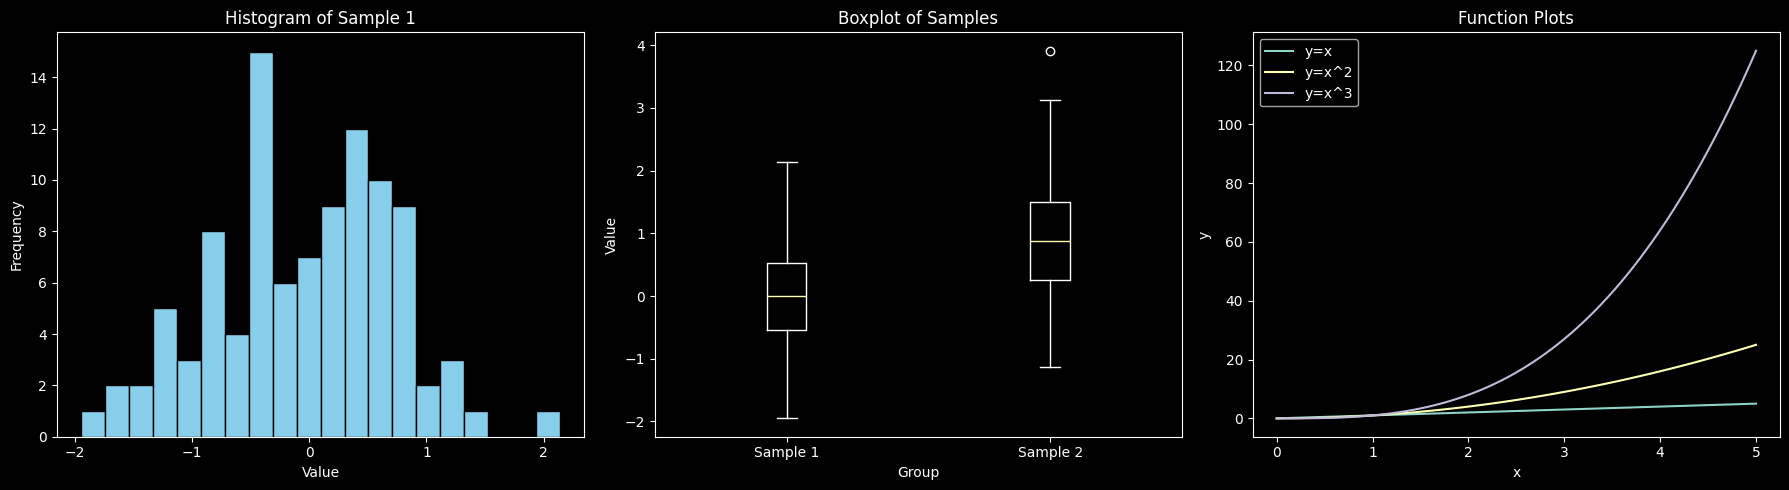

In [10]:
import numpy as np
from scipy import linalg, optimize, stats
import matplotlib.pyplot as plt
#解线性方程组并验证
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = linalg.solve(A, b)
print("方程组解:", sol)
print("验证结果:", A @ sol)
#求方程 x^2 - 2 = 0 的正负根
func = lambda x: x**2 - 2
res_pos = optimize.root(func, x0=1.0)
res_neg = optimize.root(func, x0=-1.0)
print("\n正根求解成功:", res_pos.success, "结果:", res_pos.x[0], "函数值:", res_pos.fun[0])
print("负根求解成功:", res_neg.success, "结果:", res_neg.x[0], "函数值:", res_neg.fun[0])
#求 f(x)=x^2+x+2的最小值
f = lambda x: x**2 + x + 2
min_res = optimize.minimize(f, x0=0)
print("\n数值极小点:", min_res.x[0], "数值最小值:", min_res.fun)
print("解析极小点: -0.5, 解析最小值: 1.75")
#独立样本 t 检验
rng = np.random.default_rng(42)
s1 = rng.normal(0, 1, 100)
s2 = rng.normal(1, 1, 100)
t_stat, p_val = stats.ttest_ind(s1, s2)
print(f"\nt统计量: {t_stat:.4f}, p值: {p_val:.6f}")
print("显著性判断:", "拒绝原假设 (差异显著)" if p_val < 0.05 else "不拒绝原假设")
#Matplotlib 绘图
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(s1, bins=20, color='skyblue', edgecolor='black')
axes[0].set_title("Histogram of Sample 1")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

axes[1].boxplot([s1, s2], labels=["Sample 1", "Sample 2"])
axes[1].set_title("Boxplot of Samples")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Value")

x = np.linspace(0, 5, 100)
axes[2].plot(x, x, label='y=x')
axes[2].plot(x, x**2, label='y=x^2')
axes[2].plot(x, x**3, label='y=x^3')
axes[2].set_title("Function Plots")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].legend()

plt.tight_layout()
plt.show()

实验4：pandas Series、DataFrame 与内存中的
CSV 读写

In [11]:
import pandas as pd
import numpy as np
#创建 DataFrame，设置索引并计算总分和平均分
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("=== 1. DataFrame 基本信息 ===")
print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前3行:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())
#使用 loc 和 iloc 读取 Carol 的记录，并筛选平均分 >= 80 的学生
print("\n=== 2. 索引与筛选 ===")
print("loc 读取 Carol:")
print(df.loc["Carol"])
print("\niloc 读取 Carol (索引位置为2):")
print(df.iloc[2])
print("\n平均分不低于80的学生:")
print(df[df["Average"] >= 80])
#计算列均值和行均值
print("\n=== 3. 均值计算 ===")
print("三科列均值 (axis=0):")
print(df[["Math", "English", "Python"]].mean(axis=0))
print("\n每名学生行均值 (axis=1):")
print(df[["Math", "English", "Python"]].mean(axis=1))
#apply 求最高分，agg 求聚合统计，rank 排名
print("\n=== 4. apply / agg / rank ===")
df["Max_Score"] = df[["Math", "English", "Python"]].apply(max, axis=1)
print("每名学生三科最高分:")
print(df["Max_Score"])

print("\n每科的最小值、均值、最大值:")
print(df[["Math", "English", "Python"]].agg(["min", "mean", "max"]))

df["Python_Rank"] = df["Python"].rank(ascending=False, method="min")
print("\nPython 成绩排名 (降序):")
print(df["Python_Rank"])
#按 Group 分组统计，并用 transform 添加组内 Python 平均分
print("\n=== 5. 分组统计与 transform ===")
group_stats = df.groupby("Group")[["Math", "English", "Python"]].mean()
print("每组人数及三科平均分:")
print(df.groupby("Group").agg(Count=("Math", "size"), Math_Mean=("Math", "mean"),
                               English_Mean=("English", "mean"), Python_Mean=("Python", "mean")))

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n每行增加所在组的 Python 平均分:")
print(df[["Group", "Python", "Group_Python_Mean"]])
#filter 保留 Python 平均分 >= 80 的组
print("\n=== 6. filter 过滤组 ===")
filtered_groups = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("保留的组及学生:")
print(filtered_groups[["Group", "Python"]])
#协方差矩阵与皮尔森相关系数矩阵
print("\n=== 7. 协方差与相关系数 ===")
cov_matrix = df[["Math", "English", "Python"]].cov()
corr_matrix = df[["Math", "English", "Python"]].corr()
print("协方差矩阵:")
print(cov_matrix)
print("\n皮尔森相关系数矩阵:")
print(corr_matrix)
#解释示例：Math 与 Python
cov_mp = cov_matrix.loc["Math", "Python"]
corr_mp = corr_matrix.loc["Math", "Python"]
print(f"\n【解释】Math 与 Python:")
print(f"  协方差 = {cov_mp:.2f} (>0): 表示两科成绩呈正相关趋势，即数学成绩高的学生，Python成绩也倾向于较高。")
print(f"  相关系数 = {corr_mp:.4f} (接近1): 表示两科成绩之间存在较强的线性正相关关系。")

=== 1. DataFrame 基本信息 ===
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

=== 2. 索引与筛选 ===